In [2]:
# Compute and compare CLIP embeddings of image–text pairs

In [3]:
import os
from traceback import print_tb

import numpy as np
import open_clip
import torch
import umap.plot
from PIL import Image

/home/Baldi/Projects/PycharmProjects/uni-MultiModal/.venv/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:359: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
  warnings.warn(msg, errors.NumbaWarning)
/home/Baldi/Projects/PycharmProjects/uni-MultiModal/.venv/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:359: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
  warnings.warn(msg, errors.NumbaWarning)
/home/Baldi/Projects/PycharmProjects/uni-MultiModal/.venv/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:359: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the

In [4]:
model, _, preprocess = open_clip.create_model_and_transforms('ViT-B-32', pretrained='laion2b_s34b_b79k')
model.eval()  # model in train mode by default, impacts some models with BatchNorm or stochastic depth active
tokenizer = open_clip.get_tokenizer('ViT-B-32')


In [5]:
print("Example from CLIP documentation")
image = preprocess(Image.open("img/CLIP.png")).unsqueeze(0)
text = tokenizer(["a diagram", "a dog", "a cat"])

with torch.no_grad():
    image_features = model.encode_image(image)
    text_features = model.encode_text(text)
    image_features /= image_features.norm(dim=-1, keepdim=True)
    text_features /= text_features.norm(dim=-1, keepdim=True)

    text_probs = (100.0 * image_features @ text_features.T).softmax(dim=-1)

print("Label probs:", text_probs)
print("The image most likely is \"a diagram\"")

Example from CLIP documentation
Label probs: tensor([[9.9951e-01, 4.0415e-04, 8.4107e-05]])
The image most likely is "a diagram"


In [6]:
print("Generating and comparing text-embeddings")
labels = []
samples = []
word_lists = ["nouns", "verbs"]
for file in word_lists:
    with open(f"word_lists/{file}", "r") as f:
        content = f.read().splitlines()
        samples.extend(content)
        labels.extend([file] * len(content))

#print(samples)
#print(labels)

Generating and comparing text-embeddings


<Axes: >

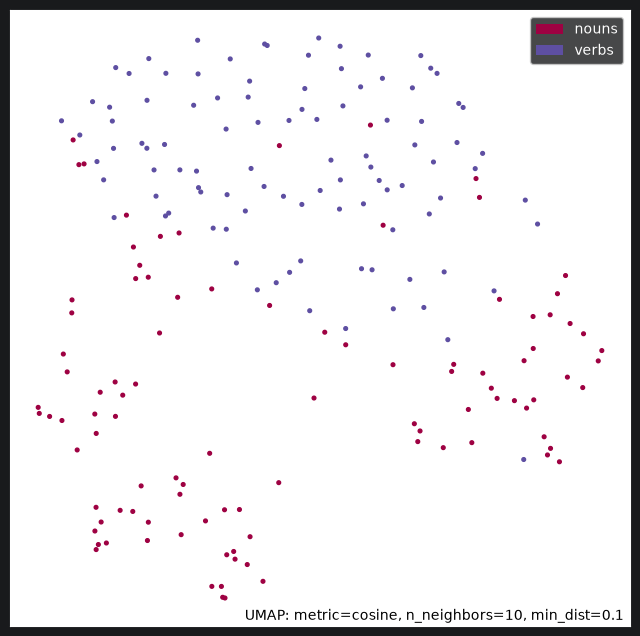

In [7]:
text = tokenizer(samples)

with torch.no_grad():
    text_features = model.encode_text(text)

example = umap.UMAP(
    n_neighbors=10, n_components=2, metric="cosine").fit(text_features)
umap.plot.points(example, labels=np.array(labels))


Generating and comparing text and image embeddings


<Axes: >

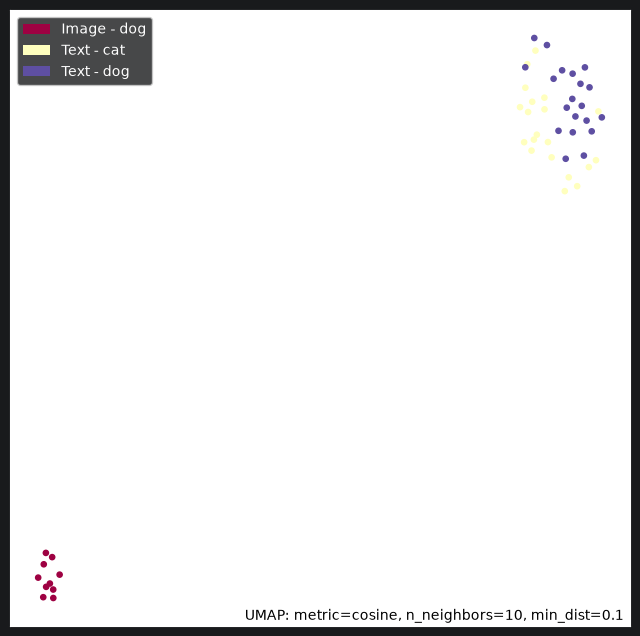

In [14]:
print("Generating and comparing text and image embeddings")

labels = []
text_samples = []
text_tokenized = []
image_samples = []
image_dir_path = "img/dogs"

with open("word_lists/cat", "r") as f:
    content = f.read().splitlines()
    text_samples.extend(content)
    labels.extend(["Text - cat"] * len(content))
with open("word_lists/dog", "r") as f:
    content = f.read().splitlines()
    text_samples.extend(content)
    labels.extend(["Text - dog"] * len(content))

for filename in os.listdir(image_dir_path):
    image_samples.append(preprocess(Image.open(f"{image_dir_path}/{filename}")).unsqueeze(0))
    labels.append("Image - dog")


text_tokenized = tokenizer(text_samples)


with torch.no_grad():
    text_features = model.encode_text(text_tokenized)

image_features = []
with torch.no_grad():
    for i in range(len(image_samples)):
        image_features.append(model.encode_image(image_samples[i]))

image_features = torch.cat(image_features, dim=0)
features = torch.cat((text_features, image_features), dim=0)
example = umap.UMAP(
    n_neighbors=10, n_components=2, metric="cosine").fit(features)
umap.plot.points(example, labels=np.array(labels))
print("The resulting embeddings seem kinda far off, that's why they were not included in the submitted file.")